In [266]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [267]:
cars_data = pd.read_csv('data_car_price.csv')
cars_data.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [268]:
cars_data.shape

(11914, 16)

# Data Preprocessing

In [269]:
cars_data.columns = cars_data.columns.str.lower().str.replace(' ', '_')
cars_data.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [270]:
cars_data.dtypes[cars_data.dtypes == 'object'].index

Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
       'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style'],
      dtype='object')

In [271]:
for col in cars_data.dtypes[cars_data.dtypes == 'object'].index :
    cars_data[col] = cars_data[col].str.lower().str.replace(' ' , '_')
cars_data.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


# EDA

<Axes: xlabel='msrp', ylabel='Count'>

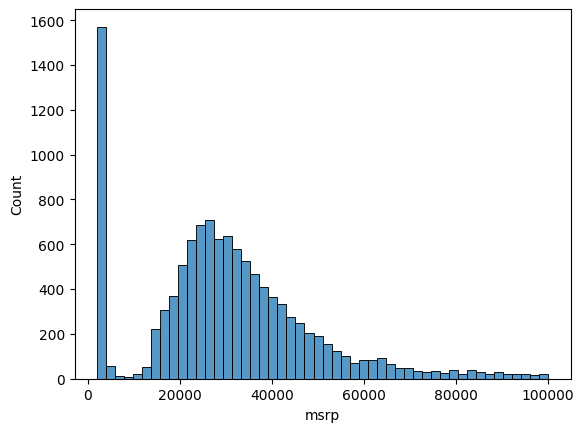

In [272]:
sns.histplot(cars_data.msrp[cars_data.msrp < 100000], bins=50)

In [273]:
prices_log = np.log1p(cars_data.msrp)
prices_log

0        10.739349
1        10.612779
2        10.500977
3        10.290483
4        10.448744
           ...    
11909    10.739024
11910    10.945018
11911    10.832122
11912    10.838031
11913    10.274913
Name: msrp, Length: 11914, dtype: float64

<Axes: xlabel='msrp', ylabel='Count'>

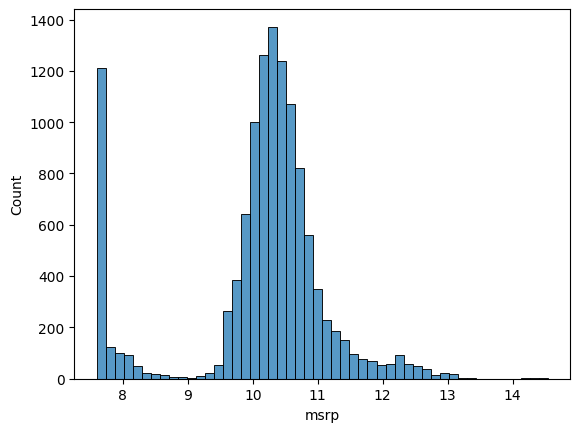

In [274]:
sns.histplot(prices_log, bins=50)

In [275]:
cars_data.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

# Data Spliting

In [276]:
len(cars_data)

11914

In [277]:
n = len(cars_data)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test
n , n_train , n_val , n_test

(11914, 7150, 2382, 2382)

In [278]:
idx = np.arange(n)
np.random.seed(2)
np.random.shuffle(idx)
idx

array([2735, 6720, 5878, ..., 6637, 2575, 7336])

In [279]:
cars_data_train = cars_data.iloc[:n_train]
cars_data_val = cars_data.iloc[n_train:n_train+n_val]
cars_data_test = cars_data.iloc[n_train+n_val:n]

In [280]:
cars_data_train = cars_data.iloc[idx[:n_train]]
cars_data_val = cars_data.iloc[idx[n_train:n_train+n_val]]
cars_data_test = cars_data.iloc[idx[n_train+n_val:n]]
cars_data_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
1902,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
9334,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
5284,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


In [281]:
cars_data_train = cars_data_train.reset_index(drop=True)
cars_data_test = cars_data_test.reset_index(drop=True)
cars_data_val = cars_data_val.reset_index(drop=True)
cars_data_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


In [282]:
target_train = np.log1p(cars_data_train.msrp.values)
target_val = np.log1p(cars_data_val.msrp.values)
target_test = np.log1p(cars_data_test.msrp.values)

In [283]:
del cars_data_train['msrp']
del cars_data_val['msrp']
del cars_data_test['msrp']

In [284]:
cars_data_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86


In [285]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

# Baseline

In [286]:
base  = ['engine_hp','engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
X_train = cars_data_train[base]
X_train = X_train.fillna(0).values
w0 , w = train_linear_regression(X_train,target_train)

In [287]:
y_pred = w0 + X_train.dot(w)

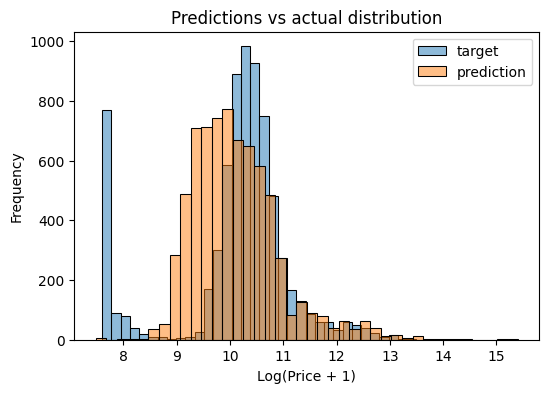

In [288]:
plt.figure(figsize=(6, 4))

sns.histplot(target_train, label='target',alpha = 0.5,  bins=40)
sns.histplot(y_pred, label='prediction', alpha = 0.5, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

## Root Mean Squared Error 

In [289]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)
rmse(target_train,y_pred)

0.7554192603920132

to choose the dataset from the data (train , validation , test)

In [290]:
def prepare_X(cars_data):
    cars_data_num = cars_data[base]
    cars_data_num = cars_data_num.fillna(0)
    X = cars_data_num.values
    return X

In [291]:
X_train = prepare_X(cars_data_train)                           #
w0 , w = train_linear_regression(X_train,target_train)

X_val = prepare_X(cars_data_val)                          
y_pred = w0 + X_val.dot(w)

rmse(target_val, y_pred)

0.761653099130156

## Simple Feature Engineering

In [292]:
def prepare_X(cars_data):                   
    cars_data = cars_data.copy()                   
    cars_data['age'] = 2017 - cars_data.year      ## 2017 is the max year
    features = base + ['age']
    
    cars_data_num = cars_data[features]
    cars_data_num = cars_data_num.fillna(0)
    X = cars_data_num.values
    return X

In [293]:
X_train = prepare_X(cars_data_train)                           #
w0 , w = train_linear_regression(X_train,target_train)

X_val = prepare_X(cars_data_val)                          
y_pred = w0 + X_val.dot(w)

rmse(target_val, y_pred)

0.5172055461058299

In [294]:
cars_data['make'].value_counts().head(5)

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

In [295]:
cars_data['number_of_doors'].value_counts()

number_of_doors
4.0    8353
2.0    3160
3.0     395
Name: count, dtype: int64

## Dealing with Categorical Values

In [296]:
def prepare_X(cars_data):                   
    cars_data = cars_data.copy()                 
    features = base.copy()
    cars_data['age'] = 2017 - cars_data.year      
    features.append('age')
    
    for v in [2, 3, 4]:                     
        feature = 'num_doors_%s' % v      
        cars_data[feature] = (cars_data['number_of_doors'] == v).astype(int)   
        features.append(feature)      

    for v in ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']:      
        feature = 'is_make_%s' % v
        cars_data[feature] = (cars_data['make'] == v).astype(int)
        features.append(feature)

    cars_data_num = cars_data[features]
    cars_data_num = cars_data_num.fillna(0)
    X = cars_data_num.values
    return X

In [297]:
categorical_variables = ['make','engine_fuel_type','transmission_type','driven_wheels','market_category' ,'vehicle_size','vehicle_style']
categories = {}
for c in categorical_variables:
    categories[c] = list(cars_data[c].value_counts().head().index)
categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'luxury,performance',
  'hatchback'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [298]:
def prepare_X(cars_data):                   
    cars_data = cars_data.copy()                  
    features = base.copy()
    cars_data['age'] = 2017 - cars_data.year      
    features.append('age')
    
    for v in [2, 3, 4]:                      
        feature = 'num_doors_%s' % v        
        cars_data[feature] = (cars_data['number_of_doors'] == v).astype(int)
        features.append(feature)      

    for c, values in categories.items():
        for v in values:      
            feature = '%s_%s' % (c,v)
            cars_data[feature] = (cars_data[c] == v).astype(int)
            features.append(feature)

    cars_data_num = cars_data[features]
    cars_data_num = cars_data_num.fillna(0)
    X = cars_data_num.values
    return X

In [299]:
X_train = prepare_X(cars_data_train)                           
w0 , w = train_linear_regression(X_train,target_train)

X_val = prepare_X(cars_data_val)                          
y_pred = w0 + X_val.dot(w)

rmse(target_val, y_pred)

30.23507117183833

## Regularization

over here we add a very small constant number to the diagonal of the dataset to reduces the value of the weight for better model

In [300]:
def train_linear_regression_reg(X, y, r = 0.01):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)

    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [301]:
X_train = prepare_X(cars_data_train)                           
w0 , w = train_linear_regression(X_train,target_train)

X_val = prepare_X(cars_data_val)                          
y_pred = w0 + X_val.dot(w)

rmse(target_val, y_pred)

30.23507117183833

## Tuning the model

a way to find the best "r"

In [302]:
for r in [0,0.00001,0.0001,0.001,0.01,0.1,10,100]:

    X_train = prepare_X(cars_data_train)                           
    w0 , w = train_linear_regression_reg(X_train,target_train, r =r)

    X_val = prepare_X(cars_data_val)                                      
    y_pred = w0 + X_val.dot(w)

    score = rmse(target_val, y_pred)
    print(r,w0,score)

0 6775859061080289.0 30.23507117183833
1e-05 6.590905413435901 0.4565170284506526
0.0001 6.29829381216216 0.45651706115512675
0.001 6.285877621486336 0.45651750874621566
0.01 6.276610129017163 0.4565219901456571
0.1 6.191208692817916 0.45656927630256605
10 4.283980108950864 0.4701456932100146
100 2.4990470830028264 0.5786709462476405


In [303]:
r = 0.0001

X_train = prepare_X(cars_data_train)                       
w0 , w = train_linear_regression_reg(X_train,target_train, r =r)

X_val = prepare_X(cars_data_val)                          
y_pred = w0 + X_val.dot(w)

score = rmse(target_val, y_pred)
score

0.45651706115512675

## Using the model

we combine the train and the validation dataset into one set full_train

In [304]:
full_train = pd.concat([cars_data_train,cars_data_val])
full_train.reset_index(drop = True)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9527,volvo,v60,2015,regular_unleaded,240.0,4.0,automatic,front_wheel_drive,4.0,luxury,midsize,wagon,37,25,870
9528,maserati,granturismo_convertible,2015,premium_unleaded_(required),444.0,8.0,automatic,rear_wheel_drive,2.0,"exotic,luxury,high-performance",midsize,convertible,20,13,238
9529,cadillac,escalade_hybrid,2013,regular_unleaded,332.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,hybrid",large,4dr_suv,23,20,1624
9530,mitsubishi,lancer,2016,regular_unleaded,148.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,sedan,34,24,436


In [305]:
x_full_train = prepare_X(full_train)
x_full_train

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [332.,   8.,  23., ...,   0.,   0.,   0.],
       [148.,   4.,  34., ...,   0.,   0.,   0.],
       [290.,   6.,  25., ...,   0.,   0.,   0.]])

In [306]:
y_full_train = np.concatenate([target_train,target_val])
y_full_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 11.21756062,
        9.77542688, 10.1924563 ])

In [307]:
w0 , w = train_linear_regression_reg(x_full_train,y_full_train, r =r)
w0

6.443216404772075

In [308]:
x_test = prepare_X(cars_data_test)             ####### TEST                           
y_pred = w0 + x_test.dot(w)

score = rmse(target_test, y_pred)
score

0.45177455005719364

In [309]:
car = cars_data_test.iloc[10].to_dict()
car

{'make': 'mazda',
 'model': '3',
 'year': 2016,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 155.0,
 'engine_cylinders': 4.0,
 'transmission_type': 'manual',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'compact',
 'vehicle_style': 'sedan',
 'highway_mpg': 41,
 'city_mpg': 29,
 'popularity': 586}

In [310]:
one_record = pd.DataFrame([car])
one_record

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,mazda,3,2016,regular_unleaded,155.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,sedan,41,29,586


In [311]:
x_small = prepare_X(one_record)
x_small

array([[155.,   4.,  41.,  29., 586.,   1.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.]])

## The Prediction

In [312]:
y_pred = w0 + x_small.dot(w)
np.expm1(y_pred[0])

23482.528204107584

## The Target

In [313]:
np.expm1(target_test[10])

17844.999999999993